# Exercise 1: From municipalities to counties

Each Norwegian municipality (*kommune*) belongs to a county (*fylke*). In this
exercise, you will use municipality-level data from Statistics Norway (SSB) to
compare counties by their number of municipalities, population, and population
density.

1.  Load `municipalities.csv` from the `data/ssb/` folder. Keep only the columns
    `municipality`, `county`, `population`, and `land_area`, and display the first
    five rows.

    Each row represents one municipality. The column `population` records its
    number of residents, and `land_area` records its land area in km².

2.  Group the data by `county` and count the municipalities in each county.
    Display the counts in descending order. Which county contains the most
    municipalities?

    *Hint:* Applying `size()` to a grouped DataFrame counts the rows in each group.
    Use
    [`sort_values()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.sort_values.html)
    to sort the counts.

3.  Create a DataFrame named `df_counties` containing the total population and
    total land area of each county. Report the three counties with the largest
    populations.

    Check that summing the county populations gives the same national total as
    summing the municipality populations.

4.  Add a column named `density` to `df_counties`, containing each county's
    population density in residents per km² of land:

    $$
    \text{Population density} =
    \frac{\text{Total population}}{\text{Total land area}}
    $$

    Report the three counties with the highest population densities. Does the
    county with the largest population also have the highest population density?

In [2]:
#Part 1

import pandas as pd

DATA_PATH = '../../data'
file = f'{DATA_PATH}/ssb/municipalities.csv'

df = pd.read_csv(file)

df.head(5)

,muni_id,municipality,county_id,county,population,land_area,mean_age,median_age,college_share,median_income,cars,electric_cars
0,301,Oslo,3,Oslo,724290,426,38.7,36.0,56.4,635200,246809,120469
1,4601,Bergen,46,Vestland,293709,445,40.3,38.0,46.8,671700,122239,60695
2,5001,Trondheim - Tråante,50,Trøndelag - Trööndelage,216518,496,39.5,36.0,48.0,659600,92529,37742
3,1103,Stavanger,11,Rogaland,150123,256,39.9,38.0,46.9,732600,69615,27663
4,3201,Bærum,32,Akershus,132358,189,41.4,41.0,56.4,837100,78279,38369


In [23]:
#Part 2
(df.groupby('county').agg('municipality').size()).sort_values()



county
Oslo                                 1
Vestfold                             6
Østfold                             12
Telemark                            17
Buskerud                            18
Finnmark - Finnmárku - Finmarkku    18
Akershus                            21
Troms - Romsa - Tromssa             21
Rogaland                            23
Agder                               25
Møre og Romsdal                     27
Trøndelag - Trööndelage             38
Nordland - Nordlánnda               41
Vestland                            43
Innlandet                           46
Name: municipality, dtype: int64

In [24]:
#Part 3

#groups[['population'], ['land_area']].sum
df_counties = df.groupby('county').agg(total_population = ('population', 'sum'), total_land = ('land_area', 'sum'))

df_counties.sort_values('total_population', ascending=False).head(3)

,total_population,total_land
county,,
Akershus,740680,5471
Oslo,724290,426
Vestland,655210,31964


In [25]:
#Part 4
df_counties['density'] = df_counties['total_population'] / df_counties['total_land']
df_counties.sort_values('density', ascending=False).head(3)

,total_population,total_land,density
county,,,
Oslo,724290,426,1700.211268
Akershus,740680,5471,135.382928
Vestfold,258071,2092,123.360899


***
# Exercise 2: House price levels and dispersion

For this exercise, we're using around 3,000 observations of house prices and house
characteristics from Ames, a small city in Iowa.

1.  Load the Ames housing data set from `ames_houses.csv` located in the `data/` folder.

    To familiarize yourself with the data, report the columns present in the DataFrame and 
    then restrict the data to the columns `SalePrice` (price in thousands of US dollars) 
    and `Neighborhood` (abbreviated name of the neighborhood).
    
    Count the number of observations in each neighborhood. Drop all observations
    belonging to neighborhoods with fewer than 20 observations. Use this
    restricted data set for the remainder of the exercise.

    Check that there are no observations with missing values in the final data set.

2.  Compute the average house price (column `SalePrice`) by neighborhood (column
    `Neighborhood`). List the three neighborhoods with the highest average prices,
    for example by using
    [`sort_values()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html).

    Create a bar chart showing the average sale price for all remaining
    neighborhoods in descending order.

    *Hint:* You can create the bar chart by either using pandas's 
    [`DataFrame.plot.bar()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.bar.html)
    or Matplotlib's
    [`bar()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.bar.html).

3.  You want to quantify the price dispersion in each neighborhood. To this end, compute the standard deviation of the sale price by neighborhood using 
    [`std()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.std.html).
    Which are the three neighborhoods with the most dispersed prices?

4.  Create a scatter plot with the average house price on the $x$-axis and the standard deviation on the $y$-axis.
    Is there a relationship between the average house prices and their dispersion within a neighborhood?

    *Hint:* You can create the scatter plot by either using pandas's 
    [`DataFrame.plot.scatter()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.scatter.html)
    or Matplotlib's 
    [`scatter()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html).

5.  **[Advanced]** To compare neighborhoods with different average prices,
    express the standard deviation as a percentage of the average price:

    $$
    \text{Relative price spread (\%)} =
    100 \times \frac{\text{standard deviation}}{\text{average price}}
    $$

    This is the
    [coefficient of variation](
    https://www.itl.nist.gov/div898/software/dataplot/refman2/auxillar/coefvari.htm
    )
    expressed as a percentage. For example, a standard deviation of 20 thousand
    USD and an average price of 100 thousand USD give a relative spread of 20%.

    Calculate the relative price spread for each neighborhood. Create a scatter
    plot with the average house price on the $x$-axis and the relative price spread
    on the $y$-axis. Do neighborhoods with higher average prices also have more
    dispersed prices relative to their average? Compare the pattern with Part 4.

In [26]:
#Part 1
file = f'{DATA_PATH}/ames_houses.csv'
df = pd.read_csv(file)

df.head()


,LotArea,Neighborhood,OverallQuality,OverallCondition,YearBuilt,YearRemodeled,BuildingType,CentralAir,LivingArea,Bathrooms,Bedrooms,Fireplaces,SalePrice,YearSold,MonthSold,HasGarage
0,2951.2,NAmes,6,5,1960,1960,Single-family,Y,153.8,1,3,2,215.0,2010,5,1
1,1079.6,NAmes,5,6,1961,1961,Single-family,Y,83.2,1,2,0,105.0,2010,6,1
2,1325.3,NAmes,6,6,1958,1958,Single-family,Y,123.5,1,3,0,172.0,2010,6,1
3,1036.7,NAmes,7,5,1968,1968,Single-family,Y,196.0,2,3,2,244.0,2010,4,1
4,1284.7,Gilbert,5,5,1997,1998,Single-family,Y,151.3,2,3,1,189.9,2010,3,1


In [27]:
df_new = df[['Neighborhood', 'SalePrice']]


In [28]:
#Assigning the number of observations to its neighborhood
counts = df_new.groupby('Neighborhood')['SalePrice'].transform('size')

#Keeping only the neighborhoods with more than 20 observations
df_new = df_new.loc[counts >= 20].copy()
print('Remaining neighborhoods:', len(df['Neighborhood'].value_counts()))
print(f'Remaining observations: {len(df):,d}')

Remaining neighborhoods: 28
Remaining observations: 2,930


In [29]:
#Checking for potential missing values (there are non)
df_new.info()

<class 'pandas.DataFrame'>
Index: 2909 entries, 0 to 2929
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Neighborhood  2909 non-null   str    
 1   SalePrice     2909 non-null   float64
dtypes: float64(1), str(1)
memory usage: 68.2 KB


PART 2

In [30]:
#Printing the average saleprice by neighborhood, sorting the values and restricting the output to the three highest averages
df_new.groupby('Neighborhood')['SalePrice'].mean().sort_values(ascending = False).head(3)

Neighborhood
NoRidge    330.321127
StoneBr    324.227451
NridgHt    322.019277
Name: SalePrice, dtype: float64

<Axes: xlabel='Neighborhood'>

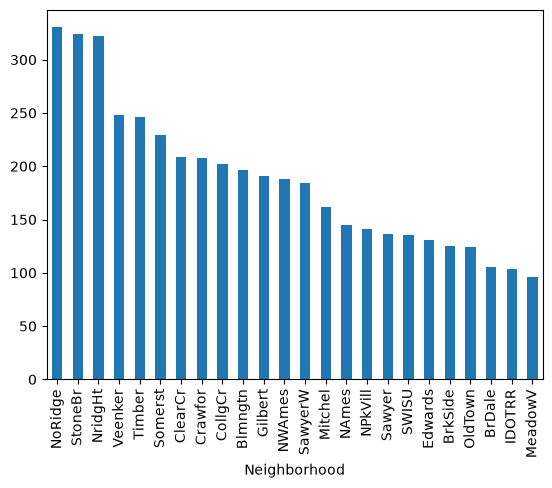

In [31]:
#Defining a dataframe with the right conditions
df_avg = df_new.groupby('Neighborhood')['SalePrice'].mean().sort_values(ascending = False)

#Creating a bar chart i descending order 
df_avg.plot.bar()

PART 3

In [32]:
#Computing the 3 neighborhoods with the most standard deviation in sales prices
df_new.groupby('Neighborhood')['SalePrice'].std().sort_values(ascending = False).head(3)

Neighborhood
StoneBr    119.270897
NoRidge    101.444018
NridgHt     95.934020
Name: SalePrice, dtype: float64

PART 4

In [33]:
df_stats = df_new.groupby('Neighborhood')['SalePrice'].agg(['mean', 'std'])


<Axes: title={'center': 'Average house price vs standard sales price deviation'}, xlabel='Average house price (thousands US dollars)', ylabel='Standard deviation (thousands US dollars)'>

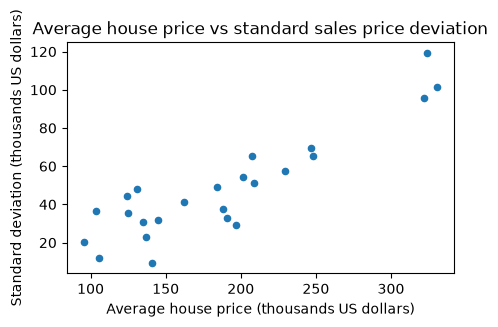

In [34]:
#making the plot with the built in plot function 
df_stats.plot.scatter(
    x = 'mean',
    y = 'std',
    title = 'Average house price vs standard sales price deviation',
    xlabel = 'Average house price (thousands US dollars)',
    ylabel = 'Standard deviation (thousands US dollars)',
    figsize = (5,3),
)

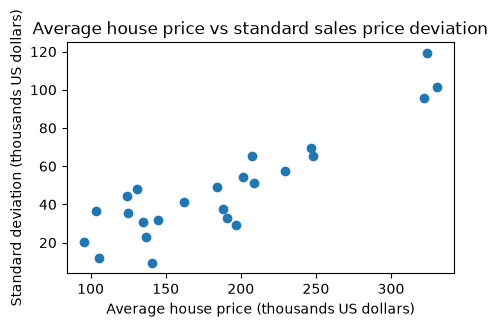

In [40]:
#using mathplotlib scatter plot function
import matplotlib.pyplot as plt

plt.figure(figsize = (5, 3))
plt.scatter(df_stats['mean'], df_stats['std'])
plt.ylabel('Standard deviation (thousands US dollars)')
plt.xlabel('Average house price (thousands US dollars)')
plt.title('Average house price vs standard sales price deviation')

plt.show()

PART 5

In [44]:
# creating a new column that expresses the relative price spread (100 * standard deviation/average price)
df_stats['relative_ps'] = df_stats['std']/df_stats['mean'] * 100


<Axes: title={'center': 'Average house price and the relative price spread'}, xlabel='Average house price', ylabel='Relative price spread (%)'>

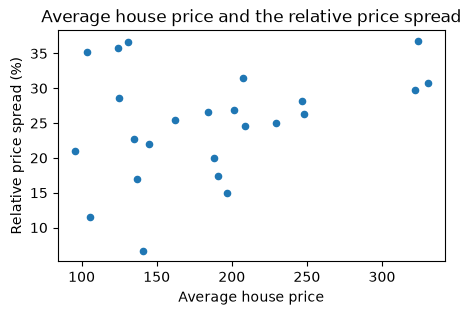

In [47]:
# creating a scatter plot with the average house prices on the x-axis and the relative price spread on the y-axis
df_stats.plot.scatter(
    x = 'mean',
    y = 'relative_ps',
    title = 'Average house price and the relative price spread',
    ylabel = 'Relative price spread (%)',
    xlabel = 'Average house price',
    figsize = (5,3),
    s = 20,
)

They are much more spread out than the scatter in the previous plot

Text(0.5, 1.0, 'Average house prices vs relative price spred')

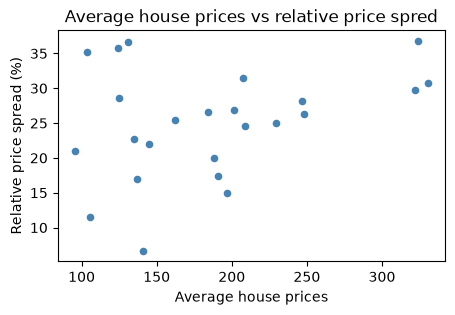

In [55]:
plt.figure(figsize = (5,3))
plt.scatter(df_stats['mean'], df_stats['relative_ps'], s = 20, c = 'steelblue')
plt.xlabel('Average house prices')
plt.ylabel('Relative price spread (%)')
plt.title('Average house prices vs relative price spred')




***
# Exercise 3: Determinants of house prices

For this exercise, we're using around 3,000 observations of house prices and house
characteristics from Ames, a small city in Iowa, to understand how house prices vary
with selected house characteristics.

1.  Load the Ames housing data set from `ames_houses.csv` located in the `data/` folder.

    Keep only the columns `SalePrice` (price in thousands of US dollars), `LotArea` (lot area in m²), `YearBuilt`, and `Bedrooms` (number of bedrooms).

    Restrict your data set to houses with one or more bedrooms and a lot area of at least 100 m².
    Report the sample size after applying these restrictions.

2.  Compute the average year in which a house was built (using the column `YearBuilt`). 

    Classify houses as _"newer"_ if they were built after the sample's average
    construction year, and _"older"_ otherwise. Store this classification in a new
    column `Newer`, with 1 for newer houses and 0 for older houses.

    What is the average year of construction within these two categories?

3.  Create a new column `Rooms` which categorizes the number of `Bedrooms` into
    three groups: 1–2, 3, and 4 or more. Use the values 2, 3, and 4 to represent
    these groups. You can create these categories using boolean indexing,
    [`np.where()`](https://numpy.org/doc/2.0/reference/generated/numpy.where.html),
    pandas's
    [`where()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.where.html),
    [`map()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.map.html),
    [`clip()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.clip.html),
    or some other way.

4.  Compute the mean sale price and number of observations within each group
    formed by `Newer` and `Rooms` (for a total of 6 different categories).

    By how much does the average price of newer houses with 4+ bedrooms exceed that
    of older houses with 1–2 bedrooms?

5.  Create a figure with two subplots arranged in two columns. The left column
    should contain a bar chart showing the average house price by the number of
    bedrooms (1–2, 3, 4+) for _older_ houses, whereas the right column should show the
    corresponding bars for _newer_ houses. Use a shared vertical scale so that prices
    can be compared across the two panels.

PART 1

In [ ]:
#reading in the file
file = f'{DATA_PATH}/ames_houses.csv'
df = pd.read_csv(file)

,LotArea,Neighborhood,OverallQuality,OverallCondition,YearBuilt,YearRemodeled,BuildingType,CentralAir,LivingArea,Bathrooms,Bedrooms,Fireplaces,SalePrice,YearSold,MonthSold,HasGarage
0,2951.2,NAmes,6,5,1960,1960,Single-family,Y,153.8,1,3,2,215.0,2010,5,1
1,1079.6,NAmes,5,6,1961,1961,Single-family,Y,83.2,1,2,0,105.0,2010,6,1
2,1325.3,NAmes,6,6,1958,1958,Single-family,Y,123.5,1,3,0,172.0,2010,6,1
3,1036.7,NAmes,7,5,1968,1968,Single-family,Y,196.0,2,3,2,244.0,2010,4,1
4,1284.7,Gilbert,5,5,1997,1998,Single-family,Y,151.3,2,3,1,189.9,2010,3,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,737.3,Mitchel,6,6,1984,1984,Single-family,Y,93.2,1,3,0,142.5,2006,3,1
2926,825.4,Mitchel,5,5,1983,1983,Single-family,Y,83.8,1,2,0,131.0,2006,6,1
2927,969.9,Mitchel,5,5,1992,1992,Single-family,Y,90.1,1,3,0,132.0,2006,7,0
2928,929.9,Mitchel,5,5,1974,1975,Single-family,Y,129.0,1,2,1,170.0,2006,4,1


In [77]:
#keeping only the specified columns
df= df[['SalePrice', 'LotArea', 'YearBuilt', 'Bedrooms']]

In [ ]:
#keeping only the rows where there are more than or exactly 1 bedroom and that has a lot area of at least 100 m^2
df = df.loc[df['Bedrooms'] >= 1]
df = df.loc[df['LotArea'] >= 100]

In [84]:
#Finding the average year in which a house was built
avg = df['YearBuilt'].mean()


In [86]:
#creating a new column with indicators showing weather a house is old or not based on the average uilding age. 
df['Newer'] = (df['YearBuilt'] >= int(avg)).astype(int)

In [ ]:
#printing the average age for the "newer" and "older" houses
df.groupby('Newer')['YearBuilt'].mean()

Newer
0    1944.412710
1    1995.058596
Name: YearBuilt, dtype: float64

In [ ]:
# making a new column 'rooms'
df['Rooms'] = df['Bedrooms']

# for all houses with 1 or 2 bedrooms, the rooms column will show 2
df.loc[df['Bedrooms'] <= 2, 'Rooms'] = 2

# for all houses with 4 or more bedrooms it will show 4 (3 is already defined since we use the 'bedrooms' column as a template)
df.loc[df['Bedrooms'] >= 4, 'Rooms'] = 4

PART 4

In [114]:
# computing the average sales price and the number of observations for the categories on 'newer' and 'rooms'
df_price_stats = df.groupby(['Newer', 'Rooms'])['SalePrice'].agg(['mean', 'count'])

# making a list with the mean prices
mean_prices = df_price_stats['mean']
mean_prices

Newer  Rooms
0      2        115.600240
       3        141.407966
       4        161.271600
1      2        211.615262
       3        209.832438
       4        271.266818
Name: mean, dtype: float64

In [116]:
#calculating the differnce in price between newer houses with 1-2 and more than 4 bedrooms
diff = mean_prices.loc[1, 4] - mean_prices.loc[0, 2]


PART 5

In [ ]:
"""Create a figure with two subplots arranged in two columns. The left column should 
contain a bar chart showing the average house price by the number of
bedrooms (1–2, 3, 4+) for _older_ houses, whereas the right column should show the
corresponding bars for _newer_ houses. Use a shared vertical scale so that prices
can be compared across the two panels."""

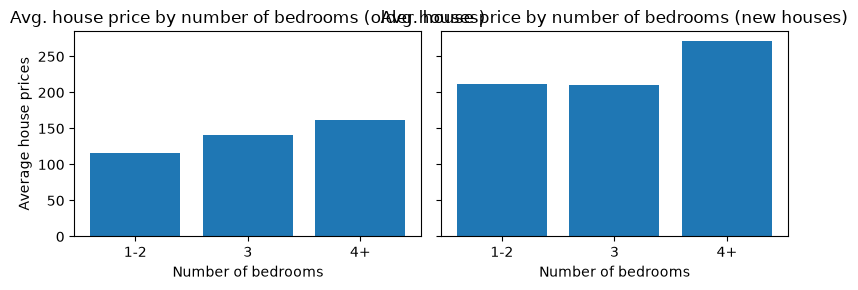

In [ ]:
#plotting the bar charts for new and old houses based on bedroms
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize = (8, 3), sharey = True)

x_values = ['1-2', '3', '4+']

axes[0].bar(x_values, mean_prices.loc[0])
axes[0].set_title('Avg. house price by number of bedrooms (older houses)')
axes[0].set_ylabel('Average house prices')
axes[0].set_xlabel('Number of bedrooms')

axes[1].bar(x_values, mean_prices.loc[1])
axes[1].set_title('Avg. house price by number of bedrooms (new houses)')
axes[1].set_xlabel('Number of bedrooms')

plt.tight_layout()

***
# Exercise 4: Inflation and unemployment in the US

In this exercise, you'll be working with monthly observations of selected
macroeconomic variables for the United States obtained from
[FRED](https://fred.stlouisfed.org/).
The data set starts in 1948 and contains observations for a total of 936 months.

1.  Load the data from the file `FRED_monthly.csv` located in the `data/FRED`
    folder. Parse `DATE` as dates and use it as the DataFrame index. Sort the
    observations in chronological order, then print the first 10 observations to
    get an idea of what the data looks like.

    Keep only the columns `Year`, `Month`, `CPI`, and `UNRATE`, retaining the date
    index. Perform this analysis only on observations prior to 1970 and drop the
    rest, leaving the sample period 1948–1969.

2.  The column `CPI` stores the consumer price index (CPI) for the US.
    Create a new column `Inflation` which contains _year-over-year inflation in
    percent_: the percent change in the CPI relative to the same month in the
    previous year. Apply
    [`pct_change()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pct_change.html)
    to the column `CPI`.

    *Hints:*

    -   Since this is monthly data, pass `periods=12` to `pct_change()` to get
        year-over-year changes.
    -   Multiply the values returned by `pct_change()` by 100 to get percent
        values.

3.  Compute the average unemployment rate (column `UNRATE`) over the restricted
    1948–1969 sample. Create a new column `UNRATE_HIGH` that contains an indicator
    whenever the unemployment rate is above its average value
    (_"high unemployment period"_).

    -   How many observations fall into the high- and low-unemployment periods?
    -   What is the average unemployment rate in the high- and low-unemployment periods?

4.  Compute the average year-over-year inflation rate for high- and
    low-unemployment periods using the available observations. Is there any
    difference?

    Visualize this relationship by creating a scatter plot with the unemployment rate on the $x$-axis and inflation on the $y$-axis, and assign different colors 
    to observations from the low- and high-unemployment periods.

5.  Use 
    [`resample()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.resample.html)
    to compute the calendar-year average of the monthly year-over-year inflation
    rates.

    -   Report the three years with the highest averages.
    -   Create a plot that shows these calendar-year averages over the sample period.

    *Hint:* Use the resampling rule `'YE'` when calling `resample()`.

In [3]:
#loading the data and reading the file. Parsing dates

file = f'{DATA_PATH}/FRED/FRED_monthly.csv'

df = pd.read_csv(file, parse_dates = ['DATE'])

#sorting the dataframes based on dates
df = df.sort_values('DATE')

#displaying the first 10 rows in the dataframe
df.head(10)

,DATE,Year,Month,CPI,UNRATE,FEDFUNDS,REALRATE,LFPART
0,1948-01-01,1948,1,23.7,3.4,NaN,NaN,58.6
1,1948-02-01,1948,2,23.7,3.8,NaN,NaN,58.9
2,1948-03-01,1948,3,23.5,4.0,NaN,NaN,58.5
3,1948-04-01,1948,4,23.8,3.9,NaN,NaN,59.0
4,1948-05-01,1948,5,24.0,3.5,NaN,NaN,58.3
5,1948-06-01,1948,6,24.2,3.6,NaN,NaN,59.2
6,1948-07-01,1948,7,24.4,3.6,NaN,NaN,59.3
7,1948-08-01,1948,8,24.4,3.9,NaN,NaN,58.9
8,1948-09-01,1948,9,24.4,3.8,NaN,NaN,58.9
9,1948-10-01,1948,10,24.3,3.7,NaN,NaN,58.7


In [4]:
#setting the index of the frame to be the date
df = df.set_index('DATE')

#restricting the dataframe to only contain the columns cited above
df = df[['Year', 'Month', 'CPI', 'UNRATE']]

In [5]:
# restricting the dataframe to only contain data from years prior to 1970

df = df.query('Year < 1970')

PART 2

In [6]:
# making a new column for inflation by computing the percentage change in CPI from month to month. Multiplying by 100 to get percentage and setting the period to twelve to get the yearly inflation

df['Inflation'] = df['CPI'].pct_change( periods = 12) * 100

PART 3

In [7]:
# computing the average unemployment rate over the selected period
avg_unrate = df['UNRATE'].mean()

In [8]:
# making a new column that uses 1 and 0 indicators to indicate weather the rate is higher or below average
df['UNRATE_HIGH'] = (df['UNRATE'] > avg_unrate).astype(int)

In [9]:
#displaying the number of years with unemployment rate above and below average
df['UNRATE_HIGH'].value_counts()

UNRATE_HIGH
0    141
1    123
Name: count, dtype: int64

In [10]:
# computing the average unemployment rate for years below and above average
df.groupby('UNRATE_HIGH')['UNRATE'].mean()

UNRATE_HIGH
0    3.697872
1    5.781301
Name: UNRATE, dtype: float64

PART 4

In [11]:
# compute the average year over year inflation rate for high and low uneployment rates
df_infl_stats = df.groupby('UNRATE_HIGH')['Inflation'].mean()

This shows that at times where the inflation was high, the unemployment rate was below average. On the other hand, where infaltion is low, the unemployment rate was above average. There is really a significant difference

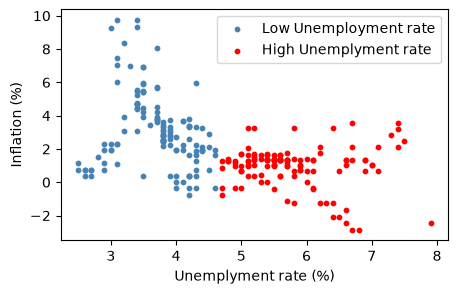

In [17]:
import matplotlib.pyplot as plt

df_hi = df.loc[df['UNRATE_HIGH'] == 1]
df_lo = df.loc[df['UNRATE_HIGH'] == 0]

plt.figure(figsize = (5, 3))

plt.scatter(
    df_lo['UNRATE'],
    df_lo['Inflation'],
    c = 'steelblue',
    label = 'Low Unemployment rate',
    s = 10,
)

plt.scatter(
    df_hi['UNRATE'],
    df_hi['Inflation'],
    c = 'red',
    s = 10,
    label = 'High Unemplyment rate'
)

plt.xlabel('Unemplyment rate (%)')
plt.ylabel('Inflation (%)')
plt.legend()



***
# Exercise 5: From ship arrivals to seasonal traffic

In this exercise, you're asked to aggregate individual ship arrivals to compare
vessel categories and seasonal traffic patterns. For this, we're using data from
Kystverket on reported arrivals at Bergen harbor for the complete calendar years
2013–2025. Each row represents one arrival, including repeat visits by the same
ship.

The file `kystverket/bergen_arrivals.csv.gz` contains four columns:

- `arrival`: Reported arrival time in Bergen local time.
- `vessel_type`: Detailed vessel type.
- `vessel_category`: Broad vessel category, such as passenger ships or
  cargo ships.
- `gross_tonnage`: Gross tonnage (GT), a measure of vessel size based on
  enclosed volume.

See the [data description](../../data/kystverket/README.md) for details.
Note that the extension `.csv.gz` indicates that the file is compressed in order to reduce the file size.

Run the supplied loading cell, then complete these tasks:

1.  Display the first five rows and report the total number of arrivals.

2.  Count arrivals by `vessel_category` and calculate each category's percentage
    of all arrivals. Display the results in descending order of arrival counts
    and create a horizontal bar chart of the counts.

    *Hint:* Use
    [`sort_values()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.sort_values.html)
    to sort the arrival counts.

    *Hint:* You can use either `plt.barh()` or `DataFrame.plot.barh()` to create the bar chart.

3.  Compute the mean `gross_tonnage` for each `vessel_category`. Display all
    categories in descending order of mean gross tonnage and create a horizontal
    bar chart of these means.

4.  Count arrivals in each month separately for `Passenger ships` and
    `Cargo ships`. Store the results in a DataFrame named `df_monthly`, with one
    column per category, and plot both monthly series in one line chart.

    *Hint:* There are several ways to implement this. One way is to compute the monthly counts for each category separately and then combine the results into a single DataFrame.

5.  Use `groupby()` to calculate average monthly arrivals for each calendar
    month, from January through December. Create two seasonal bar charts, one
    per category, with a shared vertical scale. Describe the contrast in one
    sentence.

    *Hint:* Group `df_monthly` by `df_monthly.index.month`. Replace the resulting index with the supplied `month_names`. 
    
    *Hint:* Use
    `plot.bar(subplots=True, layout=(1, 2), sharey=True)` for the two panels when plotting with the pandas plotting API.

In [19]:
import pandas as pd

# Relative path to the data directory
DATA_PATH = '../../data'
# Path to the compressed Bergen arrivals CSV file
file = f'{DATA_PATH}/kystverket/bergen_arrivals.csv.gz'

# Parse arrival times and prepare a chronological date index
df_arrivals = pd.read_csv(file, parse_dates=['arrival'], index_col='arrival')

# Sort arrivals in chronological order
df_arrivals = df_arrivals.sort_index()

# Labels for the seasonal bar charts
month_names = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec',
]

In [20]:
#Part 1

#Display the first five rows
df_arrivals.head(5)

,vessel_type,vessel_category,gross_tonnage
arrival,,,
2013-01-01 03:00:00,Platform Supply Ship,Offshore and special-purpose vessels,3350.0
2013-01-01 12:10:00,Diving Support Vessel,Offshore and special-purpose vessels,7502.0
2013-01-01 19:00:00,Offshore Support Vessel,Offshore and special-purpose vessels,8552.0
2013-01-02 01:00:00,Offshore Support Vessel,Offshore and special-purpose vessels,8552.0
2013-01-02 03:45:00,Tug,Offshore and special-purpose vessels,370.0


In [21]:
#total number of arrivals
len(df_arrivals)

45620

In [22]:
#Part 2
counts = df_arrivals.groupby('vessel_category').size()

#compute each category's share
total_arrivals = len(df_arrivals)
shares = counts / total_arrivals

shares

vessel_category
Cargo ships                             0.390158
Fishing vessels                         0.021811
Offshore and special-purpose vessels    0.283932
Passenger ships                         0.222293
Recreational vessels                    0.001096
Tankers                                 0.076458
Unknown                                 0.004253
dtype: float64

In [23]:
df_categories = pd.DataFrame({'arrivals': counts, 'share_percent': shares})

#sort by arrival count

df_categories = df_categories.sort_values('arrivals', ascending=False)

In [24]:
df_categories

,arrivals,share_percent
vessel_category,,
Cargo ships,17799,0.390158
Offshore and special-purpose vessels,12953,0.283932
Passenger ships,10141,0.222293
Tankers,3488,0.076458
Fishing vessels,995,0.021811
Unknown,194,0.004253
Recreational vessels,50,0.001096


<Axes: ylabel='vessel_category'>

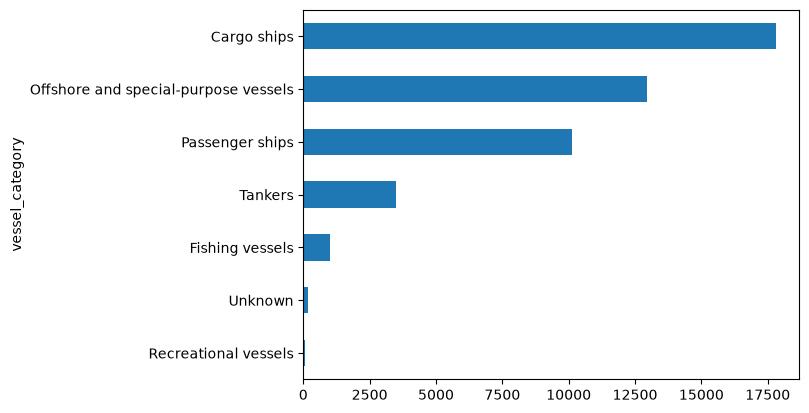

In [25]:
#Create horizontal bar chart 
import matplotlib.pyplot as plt

df_categories['arrivals'].sort_values().plot.barh()

In [26]:
avg_tonnage = df_arrivals.groupby('vessel_category')['gross_tonnage'].mean()

In [27]:
avg_tonnage = avg_tonnage.sort_values()

<Axes: ylabel='vessel_category'>

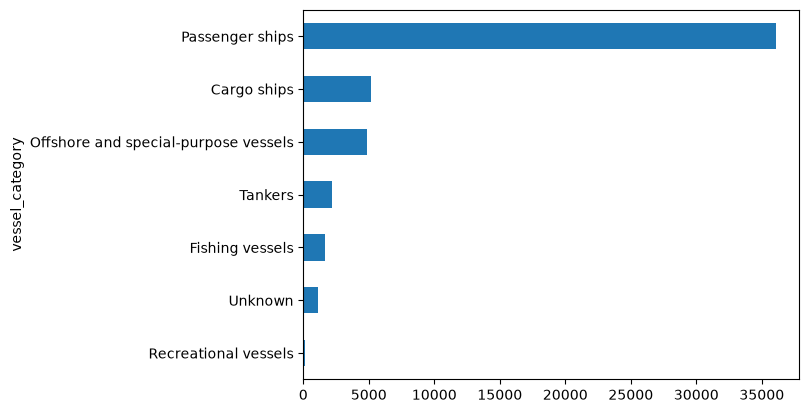

In [28]:
avg_tonnage.plot.barh()

In [29]:
#Part 4
# Categories to keep for this part
categories = ['Passenger ships', 'Cargo ships']

# Compute monthly aggregates for each vessel category
df_monthly = df_arrivals.groupby('vessel_category').resample('ME').size()

# Move the 'vessel_category' level to the columns
df_monthly = df_monthly.unstack(level='vessel_category')

# Select only the two categories of interest
df_monthly = df_monthly[categories]

df_monthly.head()

vessel_category,Passenger ships,Cargo ships
arrival,,
2013-01-31,10.0,137.0
2013-02-28,16.0,132.0
2013-03-31,18.0,149.0
2013-04-30,20.0,156.0
2013-05-31,65.0,177.0


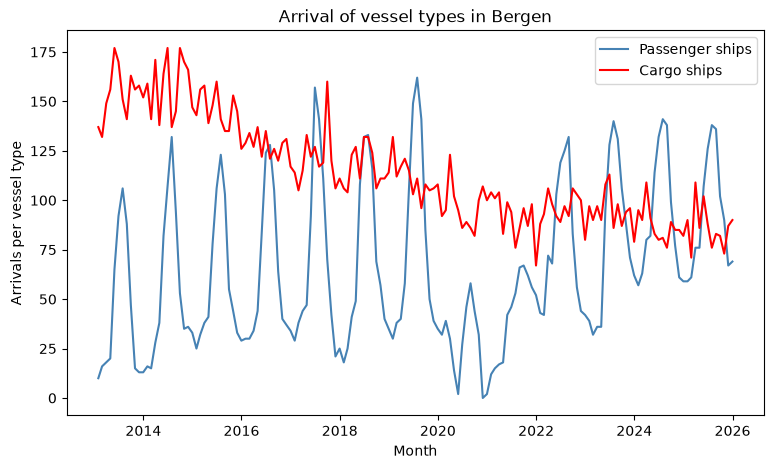

In [33]:
plt.figure(figsize = (9, 5))

plt.plot(
    df_monthly.index,
    df_monthly['Passenger ships'],
    label = 'Passenger ships',
    c = 'steelblue',
    lw = 1.5
)

plt.plot(
    df_monthly.index,
    df_monthly['Cargo ships'],
    label = 'Cargo ships',
    c = 'red',
    lw = 1.5
)

plt.xlabel('Month')
plt.ylabel('Arrivals per vessel type')
plt.title('Arrival of vessel types in Bergen')
plt.legend()

PART 5

In [35]:
#calculating the average number of arrivals by month
df_seasonal = df_monthly.groupby(df_monthly.index.month).mean()
df_seasonal.index = month_names
df_seasonal.round(1)

vessel_category,Passenger ships,Cargo ships
Jan,30.8,114.3
Feb,34.3,109.5
Mar,42.6,123.7
Apr,45.5,115.5
May,82.9,118.3
Jun,111.2,119.5
Jul,120.6,108.8
Aug,109.2,108.2
Sep,72.6,116.2
Oct,52.9,114.3


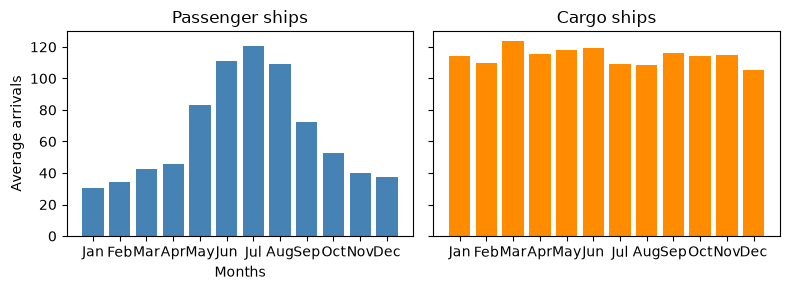

In [ ]:
#plotting bar charts in one subplot
fig, axes = plt.subplots(1, 2, figsize = (8, 3), sharey = True, sharex = True)

axes[0].bar(df_seasonal.index, df_seasonal['Passenger ships'], color = 'steelblue')
axes[0].set_xlabel('Months')
axes[0].set_ylabel('Average arrivals')
axes[0].set_title('Passenger ships')
axes[1].bar(df_seasonal.index, df_seasonal['Cargo ships'], color = 'darkorange')
axes[1].set_title('Cargo ships')

plt.tight_layout()
